# YouTube Content Moderation — biLSTM

> Arsitektur biLSTM mengacu: Sam'an & Imaddudin (2024). IJECE, 14(3).

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_score, recall_score, f1_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM,
    Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))


2026-06-14 15:31:29.164091: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781451089.358788      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781451089.418357      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781451089.905056      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781451089.905098      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781451089.905101      23 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load Dataset

In [2]:
DATA_PATH = '/kaggle/input/datasets/saidil/finaldataset/output_final_dataset.xlsx'

df = pd.read_excel(DATA_PATH)
print('Shape  :', df.shape)
print('\nLabel distribution:')
print(df['Label'].value_counts())
print(f"\nImbalance ratio: {df['Label'].value_counts()[0] / df['Label'].value_counts()[1]:.2f}x")

Shape  : (40044, 13)

Label distribution:
Label
0    23739
1    16305
Name: count, dtype: int64

Imbalance ratio: 1.46x


## 3. Preprocessing — Gabung Semua Kolom Teks

In [3]:
TEXT_COLS = ['Video Title', 'Video Tags', 'Top 20 Comments', 'Video Description', 'Transcript']

def clean_text(text):
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' url ', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['all_text'] = df[TEXT_COLS].fillna('').apply(
    lambda row: ' '.join([clean_text(str(v)) for v in row if clean_text(str(v)) != '']),
    axis=1
)

df = df[df['all_text'].str.strip() != ''].reset_index(drop=True)

token_lens = df['all_text'].str.split().str.len()
print('Shape setelah cleaning :', df.shape)
print(f'\nStatistik panjang teks:')
print(f'  rata-rata : {token_lens.mean():.0f} token')
print(f'  median    : {token_lens.median():.0f} token')
print(f'  max       : {token_lens.max()} token')
print(f'  % teks > 512 token : {(token_lens > 512).mean()*100:.1f}%')

Shape setelah cleaning : (40044, 14)

Statistik panjang teks:
  rata-rata : 1510 token
  median    : 792 token
  max       : 9522 token
  % teks > 512 token : 59.2%


## 4. Truncation — Head + Tail

In [4]:
# ─── HYPERPARAMETER ───────────────────────────────────────────────────
MAX_VOCAB     = 30000   # ukuran vocabulary
MAX_LEN       = 512     # total token = HEAD(256) + TAIL(256)
EMBED_DIM     = 128     # dimensi embedding
LSTM_UNITS    = 64      # unit LSTM per arah
DROPOUT_RATE  = 0.3     # dropout
LEARNING_RATE = 0.0001  # ← diturunkan dari 0.001, val loss naik di epoch 2 = LR terlalu besar
BATCH_SIZE    = 128     # ← dinaikkan dari 64 supaya training lebih cepat
EPOCHS        = 20
# ──────────────────────────────────────────────────────────────────────

def smart_truncate_head_tail(sequences, max_len):
    """
    Ambil HEAD (max_len//2 token pertama) + TAIL (max_len//2 token terakhir).
    Jika panjang seq <= max_len, kembalikan apa adanya.
    """
    half = max_len // 2
    truncated = []
    for seq in sequences:
        if len(seq) <= max_len:
            truncated.append(seq)
        else:
            truncated.append(seq[:half] + seq[-half:])
    return pad_sequences(truncated, maxlen=max_len, padding='post', truncating='post')

## 5. Tokenization, Split & Padding

In [5]:
X = df['all_text'].values
y = df['Label'].values

# Langkah 1: pisahkan test 15%
X_train_val_raw, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Langkah 2: dari sisa 85%, pisahkan val ~17.6% (= 15% dari total)
X_train_raw, X_val_raw, y_train_raw, y_val = train_test_split(
    X_train_val_raw, y_train_val, test_size=(15/85), random_state=42, stratify=y_train_val
)

print(f'Train : {len(X_train_raw):,} video (70%)')
print(f'Val   : {len(X_val_raw):,} video (15%)')
print(f'Test  : {len(X_test_raw):,} video (15%)')

# Tokenisasi — fit HANYA pada training
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_raw)
print('Vocab aktual:', len(tokenizer.word_index))

# Truncation + padding
X_train_full = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_train_raw), MAX_LEN)
X_val        = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_val_raw),   MAX_LEN)
X_test       = smart_truncate_head_tail(tokenizer.texts_to_sequences(X_test_raw),  MAX_LEN)

print('X_train :', X_train_full.shape)
print('X_val   :', X_val.shape)
print('X_test  :', X_test.shape)

# Class weight
class_weight_dict = {0: 0.84, 1: 1.23}
print('Class weights:', class_weight_dict)

Train : 28,030 video (70%)
Val   : 6,007 video (15%)
Test  : 6,007 video (15%)
Vocab aktual: 433264
X_train : (28030, 512)
X_val   : (6007, 512)
X_test  : (6007, 512)
Class weights: {0: 0.84, 1: 1.23}


## 6. Build Model — biLSTM


In [6]:
# ── Definisi model ────────────────────────────────────────────────────
def build_model():
    m = Sequential(name='biLSTM', layers=[
        Embedding(input_dim=MAX_VOCAB, output_dim=EMBED_DIM, input_length=MAX_LEN),
        SpatialDropout1D(0.2),
        Bidirectional(LSTM(units=LSTM_UNITS, dropout=DROPOUT_RATE)),
        Dropout(DROPOUT_RATE),
        Dense(1, activation='sigmoid')
    ])
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return m

preview = build_model()
preview.build(input_shape=(None, MAX_LEN))
preview.summary()

# ── Training ──────────────────────────────────────────────────────────
model = build_model()

final_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]

history = model.fit(
    X_train_full, y_train_raw,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=final_callbacks,
    verbose=1
)

print("\n✅ Final model training selesai.")

I0000 00:00:1781451222.248299      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781451222.254027      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "biLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 512, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 512, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,938,945 (15.03 MB)

 Trainable params: 3,938,945 (15.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


I0000 00:00:1781451228.330103      69 cuda_dnn.cc:529] Loaded cuDNN version 91002


219/219 ━━━━━━━━━━━━━━━━━━━━ 17s 52ms/step - accuracy: 0.7218 - loss: 0.6048 - val_accuracy: 0.8550 - val_loss: 0.3956
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.8607 - loss: 0.3663 - val_accuracy: 0.8745 - val_loss: 0.3455
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.8847 - loss: 0.3225 - val_accuracy: 0.8825 - val_loss: 0.3354
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.8939 - loss: 0.2930 - val_accuracy: 0.8838 - val_loss: 0.3134
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.9052 - loss: 0.2665 - val_accuracy: 0.8823 - val_loss: 0.3163
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.9139 - loss: 0.2424 - val_accuracy: 0.8785 - val_loss: 0.3321
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.9217 - loss: 0.2210 - val_accuracy: 0.8840 - val_loss: 0.3233
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.9290 - loss: 0.2023 - val_accurac

## 8. Evaluasi — Macro Metrics

In [7]:
# ── Evaluasi ──────────────────────────────────────────────────────────
# model.evaluate() sekarang hanya return 2 nilai: loss, accuracy
loss, acc = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0).flatten()
y_pred = (y_prob > 0.5).astype(int)
auc    = roc_auc_score(y_test, y_prob)

# ── Macro Metrics (dihitung manual) ───────────────────────────────────
macro_precision = precision_score(y_test, y_pred, average='macro')
macro_recall    = recall_score(y_test, y_pred,    average='macro')
macro_f1        = f1_score(y_test, y_pred,        average='macro')

# ── Cek Overfitting ───────────────────────────────────────────────────
best_epoch      = np.argmin(history.history['val_loss']) + 1
final_train_acc = history.history['accuracy'][best_epoch - 1]
final_val_acc   = history.history['val_accuracy'][best_epoch - 1]
gap             = final_train_acc - final_val_acc

print('╔══════════════════════════════════════════════════╗')
print(f'║  Best Epoch        : {best_epoch:<5}                     ║')
print(f'║  Test Accuracy     : {acc*100:6.2f}%                   ║')
print(f'║  Test Loss         : {loss:7.4f}                   ║')
print(f'║  ROC-AUC           : {auc:7.4f}                   ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Macro Precision   : {macro_precision:7.4f}                   ║')
print(f'║  Macro Recall      : {macro_recall:7.4f}                   ║')
print(f'║  Macro F1-Score    : {macro_f1:7.4f}                   ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Train Acc (best)  : {final_train_acc*100:6.2f}%                   ║')
print(f'║  Val Acc (best)    : {final_val_acc*100:6.2f}%                   ║')
print(f'║  Gap train-val     : {gap*100:5.2f}%  {"⚠️  OVERFIT" if gap > 0.05 else "✓   OK"}          ║')
print('╚══════════════════════════════════════════════════╝')

print('\nClassification Report:')
print(classification_report(
    y_test, y_pred,
    target_names=['Appropriate (0)', 'Inappropriate (1)']
))

╔══════════════════════════════════════════════════╗
║  Best Epoch        : 4                         ║
║  Test Accuracy     :  88.56%                   ║
║  Test Loss         :  0.3101                   ║
║  ROC-AUC           :  0.9373                   ║
╠══════════════════════════════════════════════════╣
║  Macro Precision   :  0.8806                   ║
║  Macro Recall      :  0.8839                   ║
║  Macro F1-Score    :  0.8821                   ║
╠══════════════════════════════════════════════════╣
║  Train Acc (best)  :  89.70%                   ║
║  Val Acc (best)    :  88.38%                   ║
║  Gap train-val     :  1.32%  ✓   OK          ║
╚══════════════════════════════════════════════════╝

Classification Report:
                   precision    recall  f1-score   support

  Appropriate (0)       0.91      0.89      0.90      3561
Inappropriate (1)       0.85      0.87      0.86      2446

         accuracy                           0.89      6007
        macro avg 

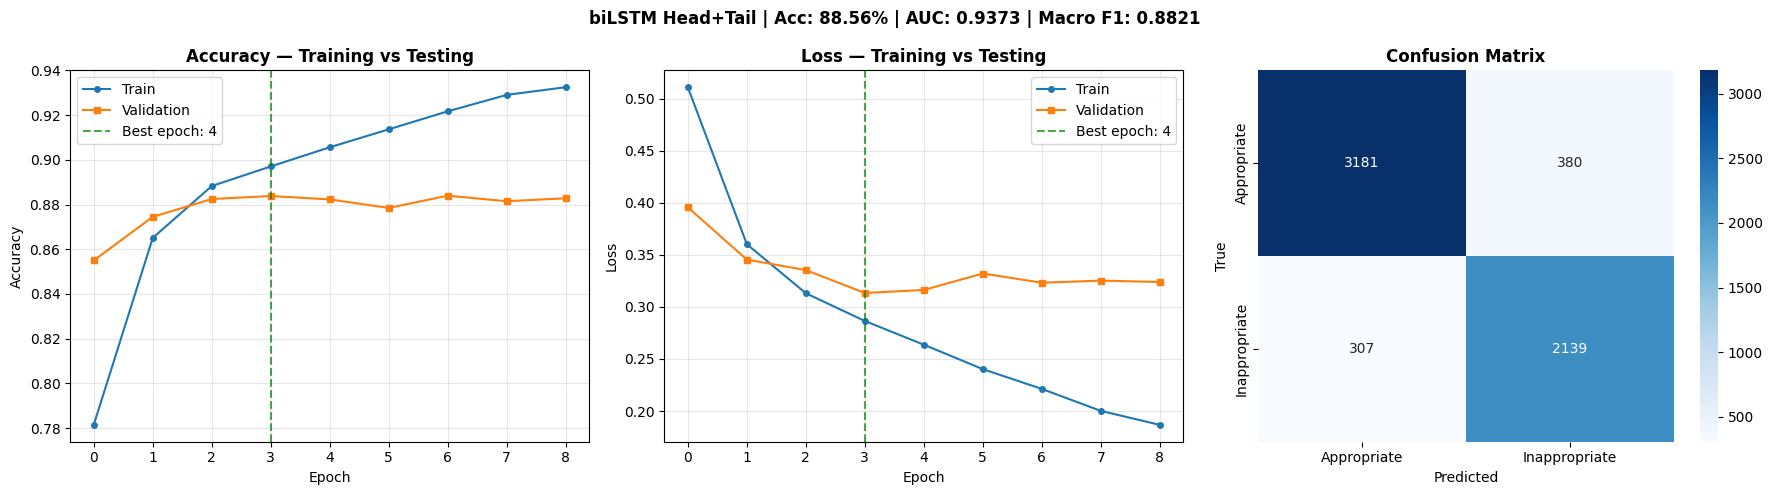

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train', marker='o', ms=4, linewidth=1.5)
axes[0].plot(history.history['val_accuracy'], label='Validation',  marker='s', ms=4, linewidth=1.5)
axes[0].axvline(best_epoch - 1, color='green', linestyle='--', alpha=0.7, label=f'Best epoch: {best_epoch}')
axes[0].set_title('Accuracy — Training vs Testing', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train', marker='o', ms=4, linewidth=1.5)
axes[1].plot(history.history['val_loss'], label='Validation',  marker='s', ms=4, linewidth=1.5)
axes[1].axvline(best_epoch - 1, color='green', linestyle='--', alpha=0.7, label=f'Best epoch: {best_epoch}')
axes[1].set_title('Loss — Training vs Testing', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Appropriate', 'Inappropriate'],
    yticklabels=['Appropriate', 'Inappropriate'],
    ax=axes[2]
)
axes[2].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('True')

plt.suptitle(
    f'biLSTM Head+Tail | Acc: {acc*100:.2f}% | AUC: {auc:.4f} | Macro F1: {macro_f1:.4f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('bilstm_headtail_result.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Save Model

In [9]:
model.save('bilstm_headtail_content_moderation.h5')
print('Model tersimpan: bilstm_headtail_content_moderation.h5')

Model tersimpan: bilstm_headtail_content_moderation.h5
